# 🪙 Crypto Trading Bot – Walk-Forward ML Backtest (BTC + ETH)
**Data:** Yahoo Finance daily candles – BTC (Sep 2014 se) aur ETH (Nov 2017 se)

**Bot ka idea:** roz subah model bolta hai *"kal price upar jayegi ya neeche?"*. Upar jaye toh coin hold karo, warna cash mein raho.

**Is project mein:**
1. **EDA** – price, returns, volatility, drawdown, BTC-ETH correlation
2. **Features** – moving averages, RSI, volatility, momentum (sirf past data se, future nahi)
3. **ML** – Logistic Regression, Decision Tree, Random Forest (80/20 time-based split)
4. **Walk-forward bot** – model har 30 din mein naye data par dobara seekhta hai ("bot seekhta rahe")
5. **Backtest** – fees ke saath, aur **Buy & Hold**, **Moving Average** aur **DCA** se comparison
6. **Mini bucket** – BTC + ETH ke beech paisa baantna (baad mein top-5 coins tak badha sakte hain)

⚠️ Ye seekhne ka project hai, financial advice nahi. Backtest asli trading ka guarantee nahi hota.
Code easy hai: **pandas + numpy** zyada (metrics bhi numpy se haath se), seaborn charts, `def` + `return` se chhota, **koi lambda nahi**, loop sirf jahan zaroori ho.

## 1. Imports

In [1]:
import numpy as np                                                # numbers aur maths ke liye
import pandas as pd                                               # data table (DataFrame) ke liye
import matplotlib.pyplot as plt                                   # charts ka base library
import seaborn as sns                                             # sundar charts ke liye
import joblib, os                                                 # model save karne aur folder banane ke liye

from sklearn.model_selection import train_test_split              # train-test split ke liye
from sklearn.linear_model import LogisticRegression               # Logistic Regression model
from sklearn.tree import DecisionTreeClassifier                   # Decision Tree model
from sklearn.ensemble import RandomForestClassifier               # Random Forest model

sns.set_theme(style="whitegrid", palette="deep")                  # seaborn ka look set karo
pd.set_option("display.width", 200)                               # table ki width badhao
os.makedirs("models", exist_ok=True)                              # models ke liye folder banao

# 💡 INSIGHT: Sirf standard libraries use hui: pandas, numpy, seaborn aur sklearn. Koi special trading library
#    nahi, taaki code easy aur samajhne layak rahe.

## 2. Data load aur quick checks

In [2]:
def load_coin(path):                                              # CSV padhne wala function
    df = pd.read_csv(path, index_col="Date", parse_dates=True)    # CSV padho, Date ko index banao
    return df[["Open", "High", "Low", "Close", "Volume"]].sort_index()  # zaroori columns rakho, date ke order mein

def quick_check(df, name):                                        # data ki sehat check karne wala function
    gaps = (df.index.to_series().diff().dt.days > 1).sum()        # kitne din ka gap hai
    ohlc_ok = ((df["Low"] <= df["Close"]) & (df["Close"] <= df["High"])).mean() * 100  # Low <= Close <= High sahi hai?
    return {"coin": name, "rows": len(df), "start": df.index.min().date(), "end": df.index.max().date(),  # rows aur dates
            "missing": int(df.isna().sum().sum()), "dup_dates": int(df.index.duplicated().sum()),         # missing aur duplicate
            "gap_days": int(gaps), "ohlc_ok_%": round(ohlc_ok, 1)}                                        # gaps aur OHLC sahi %

btc = load_coin("BTC-USD.csv")                                    # BTC ka data
eth = load_coin("ETH-USD.csv")                                    # ETH ka data
pd.DataFrame([quick_check(btc, "BTC"), quick_check(eth, "ETH")])  # dono ka checkup table

# 💡 INSIGHT: BTC ke 4,441 din (17 Sep 2014 se) aur ETH ke 3,292 din (9 Nov 2017 se). Dono mein koi missing value,
#    duplicate ya gap nahi, aur 100% rows mein Low <= Close <= High sahi hai. Data saaf hai.

,coin,rows,start,end,missing,dup_dates,gap_days,ohlc_ok_%
0,BTC,4441,2014-09-17,2026-11-13,0,0,0,100.0
1,ETH,3292,2017-11-09,2026-11-13,0,0,0,100.0


## 3. EDA – data ko samjho
Pehle dono coins ki price, daily returns aur volatility dekhte hain.

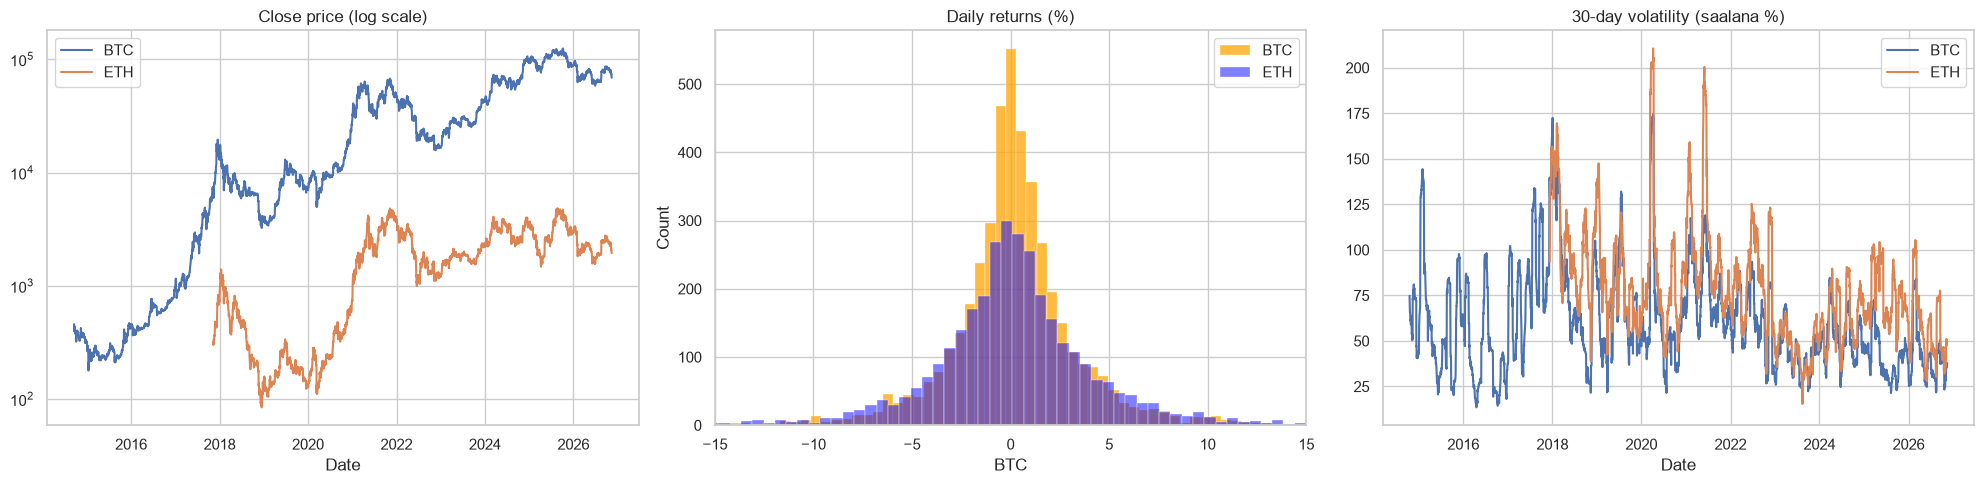

Daily return std %  -> {'BTC': 3.45, 'ETH': 4.39}
Worst day %         -> {'BTC': -37.2, 'ETH': -42.3}


In [3]:
prices = pd.concat([btc["Close"].rename("BTC"), eth["Close"].rename("ETH")], axis=1)  # dono ki closing price ek table mein
rets = prices.pct_change()                                        # daily return (%)
vol = rets.rolling(30).std() * np.sqrt(365) * 100                 # 30 din ki saalana volatility (%)

fig, ax = plt.subplots(1, 3, figsize=(20, 5))                     # 3 charts ka canvas

sns.lineplot(data=prices, ax=ax[0], dashes=False)                 # price ka line chart
ax[0].set_yscale("log"); ax[0].set_title("Close price (log scale)")  # log scale: % badhat barabar dikhe

sns.histplot(rets["BTC"].dropna() * 100, bins=120, color="orange", label="BTC", ax=ax[1])  # BTC returns ka histogram
sns.histplot(rets["ETH"].dropna() * 100, bins=120, color="blue", label="ETH", alpha=0.5, ax=ax[1])  # ETH returns ka histogram
ax[1].set_xlim(-15, 15); ax[1].legend(); ax[1].set_title("Daily returns (%)")  # x range aur title

sns.lineplot(data=vol, ax=ax[2], dashes=False)                    # volatility ka line chart
ax[2].set_title("30-day volatility (saalana %)")                  # chart ka title
plt.tight_layout(); plt.show()                                    # charts dikhao

print("Daily return std %  ->", (rets.std() * 100).round(2).to_dict())   # roz ka utaar-chadhaav
print("Worst day %         ->", (rets.min() * 100).round(1).to_dict())   # sabse kharab din

# 💡 INSIGHT: Roz ka utaar-chadhaav BTC mein ~3.45% aur ETH mein ~4.39% (std). Sabse kharab din BTC -37.2% aur ETH
#    -42.3%. Crypto mein ek din mein itna girna normal hai, isliye risk control zaroori hai.

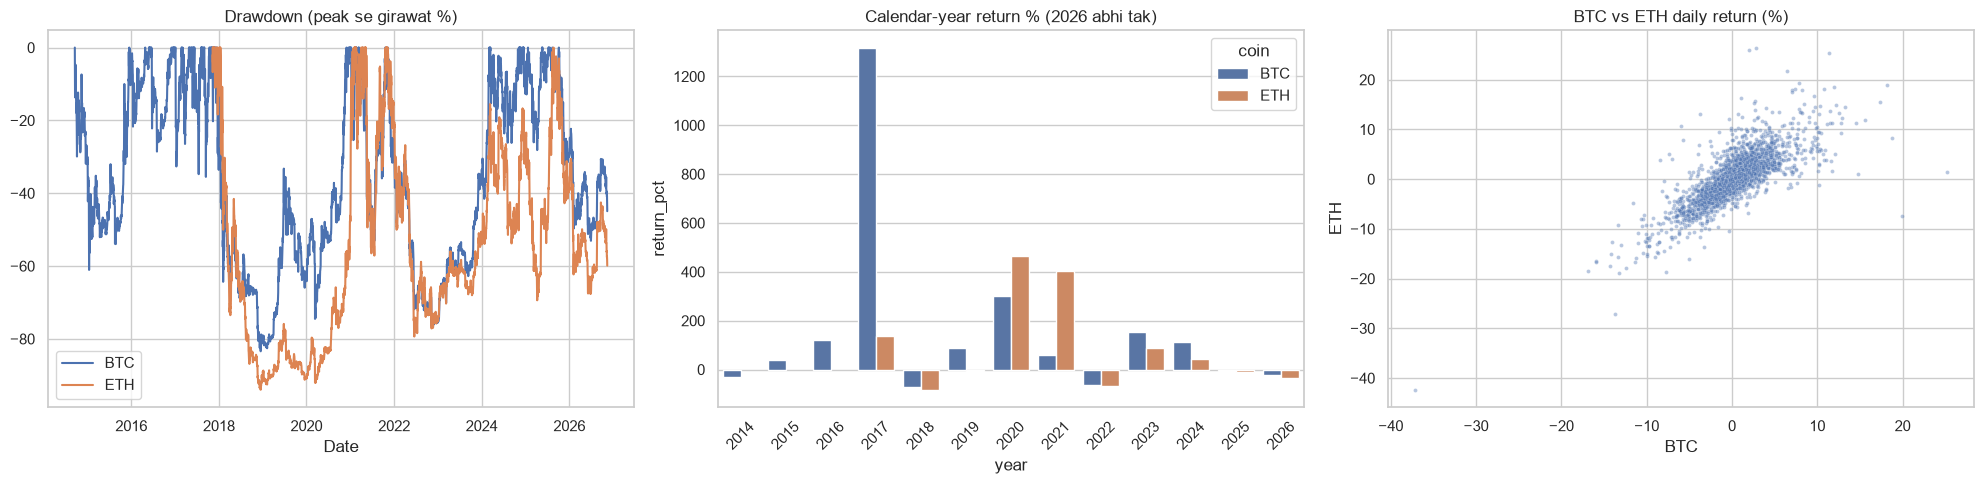

Max drawdown %: {'BTC': -83.4, 'ETH': -94.0}
BTC-ETH return correlation: 0.78


In [4]:
def drawdown(close):                                              # peak se kitna gira wala function
    return close / close.cummax() - 1                             # (aaj ki price / ab tak ka peak) - 1

dd = prices.apply(drawdown) * 100                                 # dono coins ka drawdown (%)
first = prices.groupby(prices.index.year).first()                 # har saal ki pehli price
last = prices.groupby(prices.index.year).last()                   # har saal ki aakhri price
yearly = ((last / first - 1) * 100).rename_axis("year").reset_index().melt("year", var_name="coin", value_name="return_pct")  # saal ke returns

fig, ax = plt.subplots(1, 3, figsize=(20, 5))                     # 3 charts ka canvas
sns.lineplot(data=dd, ax=ax[0], dashes=False)                     # drawdown chart
ax[0].set_title("Drawdown (peak se girawat %)")                   # chart ka title
sns.barplot(data=yearly, x="year", y="return_pct", hue="coin", ax=ax[1])  # saal-dar-saal return bar chart
ax[1].set_title("Calendar-year return % (2026 abhi tak)"); ax[1].tick_params(axis="x", rotation=45)  # title aur label
sns.scatterplot(x=rets["BTC"] * 100, y=rets["ETH"] * 100, s=8, alpha=0.4, ax=ax[2])  # BTC vs ETH daily return
ax[2].set_title("BTC vs ETH daily return (%)")                    # chart ka title
plt.tight_layout(); plt.show()                                    # charts dikhao

print("Max drawdown %:", dd.min().round(1).to_dict())             # sabse bada girawat
print("BTC-ETH return correlation:", round(rets["BTC"].corr(rets["ETH"]), 2))  # dono kitne saath chalte hain

# 💡 INSIGHT: Peak se girawat (drawdown) BTC mein -83.4% aur ETH mein -94.0% tak gayi. Saal-dar-saal return bahut
#    alag-alag hain (BTC: 2017 +1318%, 2018 -73%, 2022 -65%, 2023 +154%). BTC-ETH ka return correlation
#    0.78 hai, yani dono lagbhag saath chalte hain, isliye sirf BTC+ETH rakhne se diversification kam
#    milta hai.

## 4. Features aur Target
**Features** (aaj tak ka data se): returns, moving average gap, RSI, volatility, volume change.
**Target:** kal ka close aaj se zyada hai? (1 = haan, 0 = nahi).
Dhyan: kisi bhi feature mein *future* ka data nahi hona chahiye, warna model cheat kar lega.

In [5]:
def make_features(df):                                            # features banane wala function
    c = df["Close"]                                               # closing price
    f = pd.DataFrame(index=df.index)                              # khaali table (same dates)
    f["ret_1"] = c.pct_change(1)                                  # 1 din ka return
    f["ret_5"] = c.pct_change(5)                                  # 5 din ka return
    f["ret_10"] = c.pct_change(10)                                # 10 din ka return
    f["ret_20"] = c.pct_change(20)                                # 20 din ka return
    f["sma10_gap"] = c / c.rolling(10).mean() - 1                 # price 10-din MA se kitni upar/neeche
    f["sma20_gap"] = c / c.rolling(20).mean() - 1                 # price 20-din MA se kitni upar/neeche
    f["sma50_gap"] = c / c.rolling(50).mean() - 1                 # price 50-din MA se kitni upar/neeche
    f["sma200_gap"] = c / c.rolling(200).mean() - 1               # price 200-din MA se kitni upar/neeche
    f["sma20_vs_50"] = c.rolling(20).mean() / c.rolling(50).mean() - 1  # chhota MA bade MA se kitna upar
    f["vol_10"] = c.pct_change().rolling(10).std()                # 10 din ki volatility
    f["vol_30"] = c.pct_change().rolling(30).std()                # 30 din ki volatility
    f["range_pct"] = (df["High"] - df["Low"]) / c                 # din ka utaar-chadhaav
    f["vol_chg"] = df["Volume"] / df["Volume"].rolling(20).mean() - 1  # volume 20 din ke average se kitna alag
    delta = c.diff()                                              # roz ka price farak
    gain = pd.Series(np.where(delta > 0, delta, 0.0), index=df.index).rolling(14).mean()   # 14 din ka average fayda (numpy)
    loss = pd.Series(np.where(delta < 0, -delta, 0.0), index=df.index).rolling(14).mean()  # 14 din ka average nuksaan (numpy)
    f["rsi_14"] = 100 - 100 / (1 + gain / loss)                   # RSI (0-100, 70+ = garam, 30- = thanda)
    return f                                                      # features ka table wapas do

def build_dataset(df):                                            # features + target jodne wala function
    nxt = df["Close"].shift(-1)                                   # kal ki closing price
    target = (nxt > df["Close"]).astype(float).where(nxt.notna()) # kal upar gayi to 1, aakhri din ka target NaN
    data = make_features(df).assign(target=target).dropna()       # features + target, NaN wali rows hatao
    return data.drop(columns="target"), data["target"].astype(int)  # X aur y alag karke do

X_btc, y_btc = build_dataset(btc)                                 # BTC ka X aur y
X_eth, y_eth = build_dataset(eth)                                 # ETH ka X aur y
print("BTC:", X_btc.shape, "| ETH:", X_eth.shape)                 # dono ki shape
print("Up-day share -> BTC:", round(y_btc.mean() * 100, 1), "% | ETH:", round(y_eth.mean() * 100, 1), "%")  # kitne din price upar gayi

# 💡 INSIGHT: 200 din ke moving average ki warm-up rows hatne ke baad BTC ke 4,241 aur ETH ke 3,092 rows bache, 14
#    features ke saath. Upar jaane wale din BTC mein 52.4% aur ETH mein 51.1% hain, yani market thoda
#    upar-jhuka hai par lagbhag coin-toss jaisa.

BTC: (4241, 14) | ETH: (3092, 14)
Up-day share -> BTC: 52.4 % | ETH: 51.1 %


## 5. Train / Test split (80/20, time ke order mein)
`train_test_split` mein **`shuffle=False`**: purana 80% train, sabse naya 20% test. Crypto mein random split galat hai, kyunki model future ke din dekh leta.
Dono coins ke liye **same test period** rakhte hain (ETH ke 80/20 ke hisaab se), taaki comparison fair ho.

In [6]:
train_idx, test_idx = train_test_split(X_eth.index, test_size=0.2, shuffle=False)  # ETH ke dates ko 80/20 mein baanto
split_date = test_idx[0]                                          # test yahan se shuru
print("Test period:", split_date.date(), "to", test_idx[-1].date(), "|", len(test_idx), "din")  # test ke din

def split_by_date(X, y, d):                                       # date ke hisaab se split karne wala function
    return X[X.index < d], X[X.index >= d], y[y.index < d], y[y.index >= d]  # train/test X aur y

Xtr_btc, Xte_btc, ytr_btc, yte_btc = split_by_date(X_btc, y_btc, split_date)  # BTC split
Xtr_eth, Xte_eth, ytr_eth, yte_eth = split_by_date(X_eth, y_eth, split_date)  # ETH split
print("BTC train/test:", len(Xtr_btc), "/", len(Xte_btc), "| ETH train/test:", len(Xtr_eth), "/", len(Xte_eth))  # rows

# 💡 INSIGHT: Test period 4 Mar 2025 se 12 Nov 2026 (619 din). BTC ke train mein 3,622 din hain, ETH ke mein
#    2,473. Dono ka test period same hai, to comparison fair hai.

Test period: 2025-03-04 to 2026-11-12 | 619 din
BTC train/test: 3622 / 619 | ETH train/test: 2473 / 619


## 6. Models – kal ka direction predict karo
Metrics: **Accuracy**, **Precision**, **Recall**, **F1**, **ROC-AUC**. Saath mein **baseline "hamesha UP bolo"**, kyunki crypto mein upar jaane wale din zyada hote hain.

In [7]:
def auc_numpy(y_true, proba):                                     # ROC-AUC numpy/pandas se nikalne wala function
    ranks = pd.Series(np.asarray(proba), index=y_true.index).rank()   # probability ke ranks (chhota = 1)
    n_pos = int(y_true.sum())                                     # UP wale din ki count
    n_neg = len(y_true) - n_pos                                   # DOWN wale din ki count
    return (ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)  # rank-sum formula (Mann-Whitney)

def confusion(y_true, pred):                                      # confusion matrix pandas se banane wala function
    table = pd.crosstab(y_true.values, pred)                      # actual vs predicted ginti
    return table.reindex(index=[0, 1], columns=[0, 1], fill_value=0)  # 2x2 table (0 = DOWN, 1 = UP)

def score_row(name, y_true, proba, coin):                         # ek model ka score numpy se nikalne wala function
    y = y_true.values                                             # actual (numpy array)
    pred = np.where(np.asarray(proba) >= 0.5, 1, 0)               # probability 0.5+ to UP (1), warna DOWN (0)
    tp = np.sum((pred == 1) & (y == 1))                           # sahi UP bola
    fp = np.sum((pred == 1) & (y == 0))                           # galat UP bola
    fn = np.sum((pred == 0) & (y == 1))                           # UP tha par DOWN bola
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0               # precision
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0                # recall
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0  # F1 score
    return {"Coin": coin, "Model": name, "Accuracy": round(np.mean(pred == y), 3),  # accuracy
            "Precision": round(prec, 3), "Recall": round(rec, 3), "F1": round(f1, 3),  # precision, recall, F1
            "ROC-AUC": round(auc_numpy(y_true, proba), 3)}        # ROC-AUC (coin toss = 0.5)

def compare_models(Xtr, Xte, ytr, yte, coin):                     # teeno models train aur compare karne wala function
    mu, sd = Xtr.mean(), Xtr.std()                                # scaling ke liye train ka mean aur std
    lr = LogisticRegression(max_iter=1000).fit((Xtr - mu) / sd, ytr)  # Logistic Regression (scaled data)
    dt = DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=42).fit(Xtr, ytr)  # Decision Tree
    rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=20, n_jobs=-1, random_state=42).fit(Xtr, ytr)  # Random Forest
    rows = [score_row("Logistic Regression", yte, lr.predict_proba((Xte - mu) / sd)[:, 1], coin),  # LR ka score
            score_row("Decision Tree", yte, dt.predict_proba(Xte)[:, 1], coin),                    # DT ka score
            score_row("Random Forest", yte, rf.predict_proba(Xte)[:, 1], coin)]                    # RF ka score
    base = {"Coin": coin, "Model": "Always UP (baseline)", "Accuracy": round(yte.mean(), 3),      # baseline: hamesha UP
            "Precision": round(yte.mean(), 3), "Recall": 1.0, "F1": round(2 * yte.mean() / (1 + yte.mean()), 3), "ROC-AUC": 0.5}  # baseline ke numbers
    return pd.DataFrame(rows + [base]), rf                        # table aur RF model wapas do

res_btc, rf_btc = compare_models(Xtr_btc, Xte_btc, ytr_btc, yte_btc, "BTC")  # BTC par models
res_eth, rf_eth = compare_models(Xtr_eth, Xte_eth, ytr_eth, yte_eth, "ETH")  # ETH par models
results = pd.concat([res_btc, res_eth], ignore_index=True)        # dono ka table jodo
results                                                           # comparison table dikhao

# 💡 INSIGHT: Saare models ki accuracy 47.5% se 51.1% ke beech hai aur ROC-AUC 0.48 se 0.50 (coin toss = 0.5). BTC
#    mein best Random Forest 51.1% par baseline 'hamesha UP' (49.1%) se sirf 2 point upar. ETH mein koi
#    bhi model baseline (51.1%) ko beat nahi kar paya. Matlab in features se kal ka direction predict
#    karne mein koi pakka edge nahi mila.

,Coin,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,BTC,Logistic Regression,0.483,0.482,0.724,0.579,0.479
1,BTC,Decision Tree,0.499,0.489,0.431,0.458,0.495
2,BTC,Random Forest,0.511,0.501,0.697,0.583,0.491
3,BTC,Always UP (baseline),0.491,0.491,1.000,0.659,0.500
4,ETH,Logistic Regression,0.502,0.513,0.491,0.502,0.492
5,ETH,Decision Tree,0.477,0.482,0.335,0.396,0.482
6,ETH,Random Forest,0.475,0.485,0.462,0.473,0.491
7,ETH,Always UP (baseline),0.511,0.511,1.000,0.676,0.500


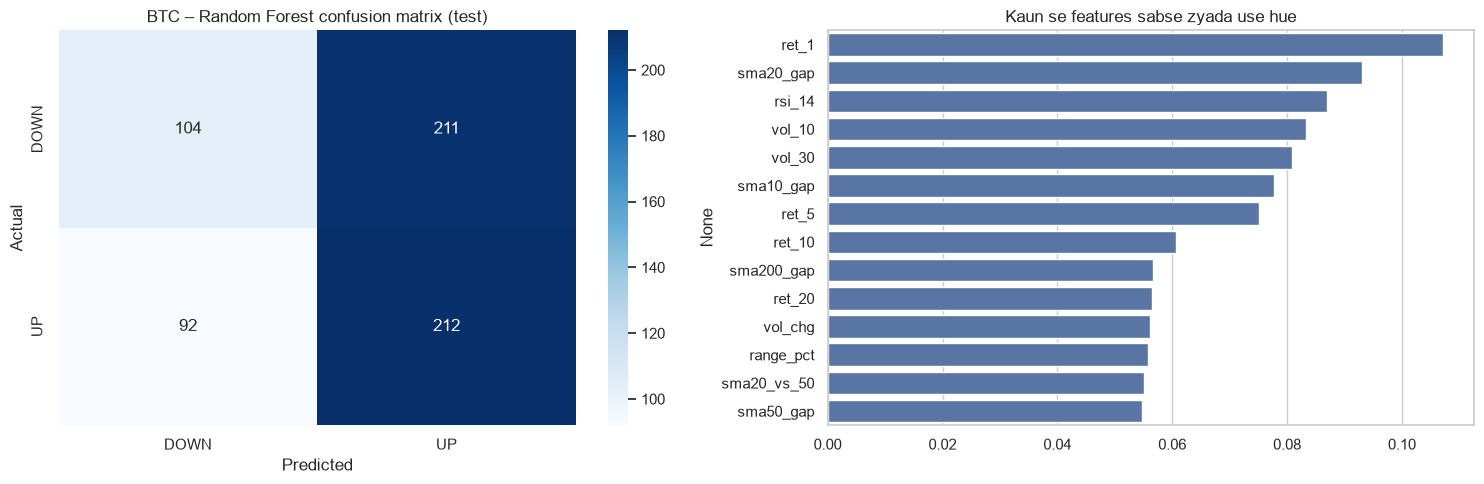

RF train accuracy: 0.634 | test accuracy: 0.511


In [8]:
proba_te = rf_btc.predict_proba(Xte_btc)[:, 1]                    # BTC test par RF ki probability
cm = confusion(yte_btc, np.where(proba_te >= 0.5, 1, 0))          # confusion matrix (pandas crosstab)
imp = pd.Series(rf_btc.feature_importances_, index=Xtr_btc.columns).sort_values(ascending=False)  # feature importance

fig, ax = plt.subplots(1, 2, figsize=(15, 5))                     # 2 charts ka canvas
sns.heatmap(cm.values, annot=True, fmt="d", cmap="Blues", xticklabels=["DOWN", "UP"], yticklabels=["DOWN", "UP"], ax=ax[0])  # heatmap
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("BTC – Random Forest confusion matrix (test)")  # labels
sns.barplot(x=imp.values, y=imp.index, ax=ax[1])                  # feature importance bar chart
ax[1].set_title("Kaun se features sabse zyada use hue")           # chart ka title
plt.tight_layout(); plt.show()                                    # charts dikhao

print("RF train accuracy:", round(rf_btc.score(Xtr_btc, ytr_btc), 3), "| test accuracy:", round(rf_btc.score(Xte_btc, yte_btc), 3))  # overfitting check

# 💡 INSIGHT: Random Forest ki train accuracy 63.4% par test accuracy 51.1%. 12 point ka farak batata hai ki model
#    ne train ka noise yaad kar liya, jo test mein kaam nahi aaya. Feature importance chart se dikhta hai
#    model ne kin features par bharosa kiya.

## 7. Walk-forward bot – "seekhta rahe"
Har **30 din** mein model **pichhle 1000 din** ke data par dobara train hota hai, aur agle 30 din ki predict karta hai. Test period ke andar kabhi future data nahi dekhta.
(Yahan ek chhota loop `list comprehension` mein hai, kyunki har window par naya model banana padta hai.)

In [ ]:
def make_rf():                                                    # Random Forest banane wala function (same settings)
    return RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=20, n_jobs=-1, random_state=42)  # RF wapas do

def walk_forward(X, y, test_start, window=1000, step=30):         # walk-forward predict karne wala function
    starts = X.index[X.index >= test_start][::step]               # har 30 din par naya training point
    def one_chunk(s):                                             # ek chunk (30 din) ka kaam
        train = X.index < s                                       # sirf s se pehle ka data
        Xtr, ytr = X[train].tail(window), y[train].tail(window)   # pichhle 1000 din ka data
        chunk = X[X.index >= s].iloc[:step]                       # agle 30 din
        return pd.Series(make_rf().fit(Xtr, ytr).predict_proba(chunk)[:, 1], index=chunk.index)  # in dino ki probability
    return pd.concat([one_chunk(s) for s in starts])              # sab chunks jodo

proba_btc = walk_forward(X_btc, y_btc, split_date)                # BTC ki walk-forward probability
proba_eth = walk_forward(X_eth, y_eth, split_date)                # ETH ki walk-forward probability
common = proba_btc.index.intersection(proba_eth.index)            # dono ke common test dates
proba_btc, proba_eth = proba_btc.loc[common], proba_eth.loc[common]  # same dates par rakho
yte = y_btc.loc[common]                                           # BTC ka asli target (check ke liye)

print("Walk-forward days:", len(common), "|", common[0].date(), "to", common[-1].date())  # test din
print("BTC walk-forward accuracy:", round(np.mean(np.where(proba_btc >= 0.5, 1, 0) == yte.values), 3), "| ROC-AUC:", round(auc_numpy(yte, proba_btc), 3))  # BTC score
yte_eth_c = y_eth.loc[common]                                     # ETH ka asli target (same dates)
print("ETH walk-forward accuracy:", round(np.mean(np.where(proba_eth >= 0.5, 1, 0) == yte_eth_c.values), 3), "| ROC-AUC:", round(auc_numpy(yte_eth_c, proba_eth), 3))  # ETH score

# 💡 INSIGHT: Walk-forward (har 30 din mein dobara train) bhi koi edge nahi laya: BTC accuracy 48.8% (ROC-AUC
#    0.483), ETH 50.7% (ROC-AUC 0.511). Model ko baar baar naya data dene se bhi kal ka direction predict
#    nahi hua.

## 8. Backtest – kya bot paisa banata?
- Roz close par decision, **agle din ka return** milta hai (koi future cheating nahi)
- **Fee 0.1%** har baar jab position badle (khareedna ya bechna)
- Comparison: **Buy & Hold**, **Moving Average crossover (20/50)**, aur ML bot

In [ ]:
def to_position(proba, thr=0.5):                                  # probability se position (1/0) banane wala function
    return pd.Series(np.where(proba >= thr, 1, 0), index=proba.index)  # thr se upar = hold (1), warna cash (0)

def ma_position(close, fast=20, slow=50):                         # moving average crossover ka position function
    signal = close.rolling(fast).mean() > close.rolling(slow).mean()  # chhota MA bade MA se upar?
    return pd.Series(np.where(signal, 1, 0), index=close.index)   # haan to hold (1), nahi to cash (0)

def run_strategy(close, pos, fee=0.001):                          # ek coin ka backtest function
    next_ret = close.pct_change().shift(-1).loc[pos.index]        # agle din ka return
    trades = pos.diff().abs().fillna(pos.abs())                   # position badli to trade (fee lagegi)
    net = (pos * next_ret - trades * fee).iloc[:-1]               # return minus fee (aakhri din hata do)
    return net, pos                                               # strategy ka return aur position do

def run_bucket(probas, closes, thr=0.5, fee=0.001):               # BTC+ETH bucket ka backtest function
    hold = pd.DataFrame(np.where(probas >= thr, 1.0, 0.0), index=probas.index, columns=probas.columns)  # jis coin ki probability high wo hold
    w = hold.div(hold.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)  # selected coins mein barabar baanto
    nxt = closes.pct_change().shift(-1).loc[w.index]              # agle din ke returns
    turnover = w.diff().abs().sum(axis=1).fillna(w.abs().sum(axis=1))  # kitna paisa idhar-udhar hua
    net = ((w * nxt).sum(axis=1) - turnover * fee).iloc[:-1]      # return minus fee
    return net, w                                                 # return aur weights do

def count_trades(pos):                                            # trades gine wala function
    return int(pos.diff().abs().fillna(pos.abs()).sum())          # kitni baar position badli

def perf(net, name, n_trades, exposure):                          # performance numbers wala function
    eq = (1 + net).cumprod()                                      # paisa kaise badha (equity curve)
    years = len(net) / 365                                        # kitne saal
    sharpe = net.mean() / net.std() * np.sqrt(365) if net.std() > 0 else 0.0  # return per risk
    return {"Strategy": name, "Total return %": round((eq.iloc[-1] - 1) * 100, 1),  # kul return
            "CAGR %": round((eq.iloc[-1] ** (1 / years) - 1) * 100, 1),             # saalana return
            "Sharpe": round(sharpe, 2), "Max drawdown %": round((eq / eq.cummax() - 1).min() * 100, 1),  # Sharpe aur sabse bada girawat
            "Trades": n_trades, "Days in market %": round(exposure * 100, 1)}       # trades aur market mein kitne din

closes = prices[["BTC", "ETH"]]                                   # dono ki closing price
probas = pd.concat([proba_btc.rename("BTC"), proba_eth.rename("ETH")], axis=1)  # dono ki probability ek table mein
hold_all = pd.Series(1, index=common)                             # hamesha hold (Buy & Hold)

net_bh_btc, p1 = run_strategy(closes["BTC"], hold_all)            # BTC Buy & Hold
net_bh_eth, p2 = run_strategy(closes["ETH"], hold_all)            # ETH Buy & Hold
net_bh_mix, w_mix = run_bucket(pd.DataFrame(1.0, index=common, columns=["BTC", "ETH"]), closes)  # 50/50 Buy & Hold
ma_btc = ma_position(btc["Close"]).loc[common]                   # BTC MA crossover position
ma_eth = ma_position(eth["Close"]).loc[common]                   # ETH MA crossover position
net_ma_btc, p3 = run_strategy(closes["BTC"], ma_btc)              # BTC MA strategy
net_ma_eth, p4 = run_strategy(closes["ETH"], ma_eth)              # ETH MA strategy
net_ml_btc, p5 = run_strategy(closes["BTC"], to_position(proba_btc))  # BTC ML bot
net_ml_eth, p6 = run_strategy(closes["ETH"], to_position(proba_eth))  # ETH ML bot
net_ml_mix, w_ml = run_bucket(probas, closes)                     # BTC+ETH ML bucket

table = pd.DataFrame([                                            # sab strategies ka comparison table
    perf(net_bh_btc, "Buy & Hold BTC", 1, 1.0), perf(net_bh_eth, "Buy & Hold ETH", 1, 1.0),  # Buy & Hold
    perf(net_bh_mix, "Buy & Hold 50/50", 2, 1.0),                                             # 50/50
    perf(net_ma_btc, "MA crossover BTC", count_trades(p3), p3.mean()), perf(net_ma_eth, "MA crossover ETH", count_trades(p4), p4.mean()),  # MA
    perf(net_ml_btc, "ML bot BTC", count_trades(p5), p5.mean()), perf(net_ml_eth, "ML bot ETH", count_trades(p6), p6.mean()),            # ML bot
    perf(net_ml_mix, "ML bucket BTC+ETH", int((w_ml.diff().abs().sum(axis=1) > 0).sum()), w_ml.sum(axis=1).mean())])                    # ML bucket
table                                                             # table dikhao

# 💡 INSIGHT: Test period mein Buy & Hold BTC -18.3%, ETH -7.1%, 50/50 -10.2%. ML bot BTC -18.2% (185 trades), ETH
#    +0.4%, bucket -18.4% (301 trades), yani ML bot buy-and-hold se behtar nahi. Moving average crossover
#    sabse achha: BTC +16.1% (drawdown -32.0% vs -53.1%) aur ETH +32.4%, par sirf 16 aur 10 trades, to ye
#    pakka saboot nahi, ho sakta hai girte market mein bas bach gaya.

,Strategy,Total return %,CAGR %,Sharpe,Max drawdown %,Trades,Days in market %
0,Buy & Hold BTC,-18.3,-11.2,-0.07,-53.1,1,100.0
1,Buy & Hold ETH,-7.1,-4.3,0.27,-67.6,1,100.0
2,Buy & Hold 50/50,-10.2,-6.1,0.14,-60.0,2,100.0
3,MA crossover BTC,16.1,9.2,0.47,-32.0,16,53.3
4,MA crossover ETH,32.4,18.0,0.60,-47.3,10,49.3
5,ML bot BTC,-18.2,-11.2,-0.21,-48.7,185,50.2
6,ML bot ETH,0.4,0.2,0.27,-63.8,199,55.1
7,ML bucket BTC+ETH,-18.4,-11.3,-0.00,-62.7,301,69.6


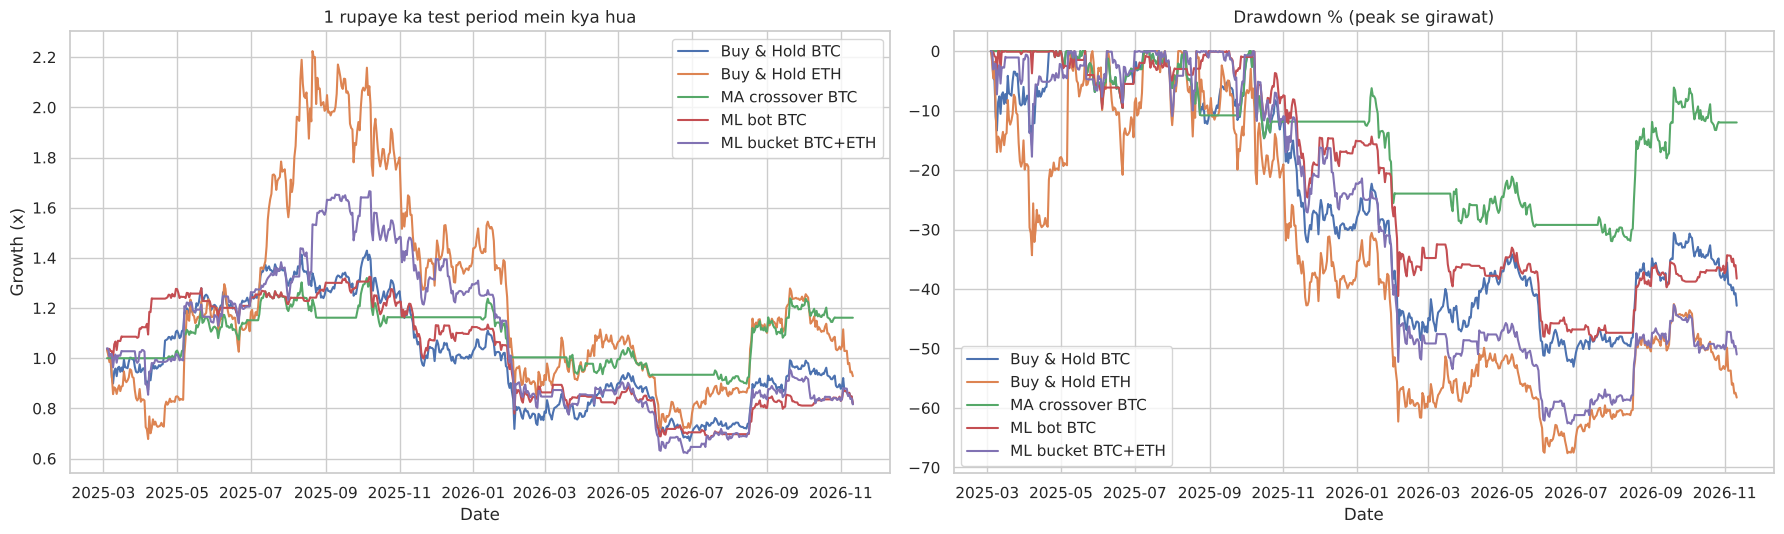

In [ ]:
def equity(net, name):                                            # paisa kaise badha wala function
    return (1 + net).cumprod().rename(name)                       # 1 rupaye ka kitna hua

curves = pd.concat([equity(net_bh_btc, "Buy & Hold BTC"), equity(net_bh_eth, "Buy & Hold ETH"),  # Buy & Hold curves
                    equity(net_ma_btc, "MA crossover BTC"), equity(net_ml_btc, "ML bot BTC"),    # MA aur ML curves
                    equity(net_ml_mix, "ML bucket BTC+ETH")], axis=1)                            # bucket curve

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))                   # 2 charts ka canvas
sns.lineplot(data=curves, ax=ax[0], dashes=False)                 # equity curves
ax[0].set_title("1 rupaye ka test period mein kya hua"); ax[0].set_ylabel("Growth (x)")  # title aur label
dd_curves = curves / curves.cummax() - 1                          # sabka drawdown
sns.lineplot(data=dd_curves * 100, ax=ax[1], dashes=False)        # drawdown chart
ax[1].set_title("Drawdown % (peak se girawat)")                   # chart ka title
plt.tight_layout(); plt.show()                                    # charts dikhao

# 💡 INSIGHT: Chart mein MA crossover ka drawdown BTC buy-and-hold se kam dikhta hai (-32.0% vs -53.1%). ML bot ki
#    curve buy-and-hold ke aas-paas ghoomti hai, usse upar nahi nikalti.

## 9. Sensitivity – threshold aur fee ka asar
Threshold badhao toh bot kam trade karta hai (sirf pakki lagne wali probability par). Fee badhao toh trade-heavy strategy ka fayda ghatta hai.

In [ ]:
def ml_row(label, proba, close, thr, fee):                        # ek setting ka result nikalne wala function
    net, pos = run_strategy(close, to_position(proba, thr), fee)    # us setting par backtest
    return perf(net, label, count_trades(pos), pos.mean())        # performance row wapas do

sens = pd.DataFrame([ml_row("BTC thr 0.50, fee 0%", proba_btc, closes["BTC"], 0.50, 0.0),    # fee ke bina
                     ml_row("BTC thr 0.50, fee 0.1%", proba_btc, closes["BTC"], 0.50, 0.001), # fee ke saath
                     ml_row("BTC thr 0.52, fee 0.1%", proba_btc, closes["BTC"], 0.52, 0.001), # thoda strict
                     ml_row("BTC thr 0.55, fee 0.1%", proba_btc, closes["BTC"], 0.55, 0.001), # aur strict
                     ml_row("BTC thr 0.50, fee 0.3%", proba_btc, closes["BTC"], 0.50, 0.003)])# mehengi fee
sens                                                              # table dikhao

# 💡 INSIGHT: Fee ke bina BTC bot -1.6% par tha, 0.1% fee ke saath -18.2% (185 trades), aur 0.3% fee par -43.5%.
#    Yaani fees ne bahut nuksaan kiya. Threshold 0.55 karne se trades 89 aur market mein 17% din hue, par
#    phir bhi -12.3%. Fee ke bina bhi bot positive nahi tha, to problem edge ki hai, sirf fee ki nahi.

,Strategy,Total return %,CAGR %,Sharpe,Max drawdown %,Trades,Days in market %
0,"BTC thr 0.50, fee 0%",-1.6,-0.9,0.13,-44.0,185,50.2
1,"BTC thr 0.50, fee 0.1%",-18.2,-11.2,-0.21,-48.7,185,50.2
2,"BTC thr 0.52, fee 0.1%",-10.8,-6.5,-0.09,-43.9,159,34.1
3,"BTC thr 0.55, fee 0.1%",-12.3,-7.5,-0.18,-34.9,89,17.3
4,"BTC thr 0.50, fee 0.3%",-43.5,-28.7,-0.88,-59.3,185,50.2


## 10. DCA (har mahine barabar paisa lagana) – "averaging"
Har mahine ke pehle din fixed amount (100) ka coin khareedo. Ye alag tarah ka comparison hai, kyunki paisa dheere-dheere lagta hai.

In [ ]:
def dca_result(close, monthly=100):                               # DCA ka result nikalne wala function
    month_price = close.resample("MS").first()                    # har mahine ke pehle din ki price
    units = np.sum(monthly / month_price)                         # kul kitne coin mile (numpy sum)
    invested = monthly * len(month_price)                         # kul kitna paisa lagaya
    value = units * close.iloc[-1]                                # aaj ki value
    return {"Coin": close.name, "Months": len(month_price), "Invested": invested,  # mahine aur invest
            "Final value": round(value, 1), "Return %": round((value / invested - 1) * 100, 1)}  # aakhri value aur return

dca = pd.DataFrame([dca_result(closes["BTC"].loc[common], 100), dca_result(closes["ETH"].loc[common], 100)])  # test period mein DCA
dca                                                               # table dikhao

# 💡 INSIGHT: 21 mahine ke test period mein har mahine 100 lagane par BTC mein 2,100 ka 1,788 (-14.9%) aur ETH
#    mein 1,771 (-15.7%) hua. Ye period girawat wala tha, isliye DCA bhi negative raha. DCA risk kam
#    karta hai, return ki guarantee nahi.

,Coin,Months,Invested,Final value,Return %
0,BTC,21,2100,1788.1,-14.9
1,ETH,21,2100,1771.2,-15.7


## 11. Models save karo

In [ ]:
def fit_final(X, y, window=1000):                                 # final model banane wala function
    return make_rf().fit(X.tail(window), y.tail(window))          # sabse nayi 1000 din par train

joblib.dump(fit_final(X_btc, y_btc), "models/btc_direction_rf.joblib", compress=5)  # BTC model save
joblib.dump(fit_final(X_eth, y_eth), "models/eth_direction_rf.joblib", compress=5)  # ETH model save
joblib.dump(list(X_btc.columns), "models/feature_columns.joblib") # features ki list save
results.to_csv("models/model_comparison.csv", index=False)        # model comparison save
table.to_csv("models/backtest_results.csv", index=False)          # backtest results save
print(os.listdir("models"))                                       # saved files dikhao

# 💡 INSIGHT: 5 files save hui: BTC aur ETH ke Random Forest (sabse nayi 1000 din par train), feature columns ki
#    list, model comparison aur backtest results CSV. Ye saved models profit ki guarantee nahi hain, bas
#    backend demo ke liye hain.

['model_comparison.csv', 'eth_direction_rf.joblib', 'feature_columns.joblib', 'backtest_results.csv', 'btc_direction_rf.joblib']


## 12. Final Summary

In [ ]:
print("MODEL COMPARISON (test period)"); print(results.to_string(index=False))  # model table
print("\nBACKTEST (fee 0.1%)"); print(table.to_string(index=False))           # backtest table

# 💡 INSIGHT: Ek line mein: data aur backtest ka pipeline sahi bana, par ML model ko kal ka direction predict
#    karne mein koi edge nahi mila, aur bot buy-and-hold se behtar nahi nikla. Sirf simple moving average
#    crossover aage dekhne layak hai, par uske trades kam hain.

MODEL COMPARISON (test period)
Coin                Model  Accuracy  Precision  Recall    F1  ROC-AUC
 BTC  Logistic Regression     0.483      0.482   0.724 0.579    0.479
 BTC        Decision Tree     0.499      0.489   0.431 0.458    0.495
 BTC        Random Forest     0.511      0.501   0.697 0.583    0.491
 BTC Always UP (baseline)     0.491      0.491   1.000 0.659    0.500
 ETH  Logistic Regression     0.502      0.513   0.491 0.502    0.492
 ETH        Decision Tree     0.477      0.482   0.335 0.396    0.482
 ETH        Random Forest     0.475      0.485   0.462 0.473    0.491
 ETH Always UP (baseline)     0.511      0.511   1.000 0.676    0.500

BACKTEST (fee 0.1%)
         Strategy  Total return %  CAGR %  Sharpe  Max drawdown %  Trades  Days in market %
   Buy & Hold BTC           -18.3   -11.2   -0.07           -53.1       1             100.0
   Buy & Hold ETH            -7.1    -4.3    0.27           -67.6       1             100.0
 Buy & Hold 50/50           -10.2    -6.1 

## ✅ Conclusion

**Kya banaya:** BTC aur ETH ke daily data par end-to-end pipeline: cleaning checks, EDA, features (sirf past data se), 80/20 time-based split, 3 models, walk-forward retraining, fees ke saath backtest, aur Buy & Hold, Moving Average aur DCA se comparison.

**Sabse zaroori nateeja (seedhi baat):**
- **ML model ko kal ka direction predict karne mein koi pakka edge nahi mila.** Accuracy 47.5%–51.1% rahi aur ROC-AUC ≈ 0.5 (coin toss). ETH mein koi model "hamesha UP" baseline ko beat nahi kar paya.
- **Walk-forward bot bhi buy-and-hold se behtar nahi nikla.** BTC bot -18.2% vs Buy & Hold -18.3%; BTC+ETH bucket -18.4%.
- **Fees ne bahut nuksaan kiya:** 185 trades par BTC bot fee ke bina -1.6% tha, 0.1% fee ke saath -18.2%.
- **Moving Average crossover (20/50) sabse achha raha** (BTC +16.1%, ETH +32.4%), par sirf 16 aur 10 trades hain aur test period girawat wala tha, to ye saboot nahi, sirf ek signal hai.
- **Train 63.4% vs test 51.1%:** model ne noise yaad kar liya (overfitting).

**Limits (dhyan rakhna):**
- Sirf **2 coins** (BTC, ETH). Top-5 bucket ke liye har period ka market-cap data chahiye, warna aaj ke top 5 chunne se survivorship bias aata hai.
- Test period sirf ~20 mahine (619 din) aur ek hi market phase (girawat/sideways) hai.
- Fee 0.1% maani hai, slippage nahi joda, aur 50/50 rebalancing cost nahi joda.
- Ye backtest hai, asli trading nahi. Ye financial advice nahi hai.

**Aage kya try kar sakte ho (test par tune mat karna, alag validation set rakho):**
1. Kal ki jagah **hafte bhar ka direction** predict karna (daily bahut noisy hai).
2. **Trend filter:** sirf tab trade karo jab price 200-din MA ke upar ho.
3. **Volatility ke hisaab se position size** (zyada volatility par kam paisa).
4. Zyada coins aur market-cap data jodo, **har period ke top 5** chuno.

**Interview mein kaise bolna:** "Maine time-based split, walk-forward retraining aur fees ke saath backtest kiya. Model buy-and-hold se behtar nahi nikla, aur maine ye sach likha. Isse seekha ki daily crypto direction predict karna mushkil hai, aur fees edge khaa jaati hain."